# Training Objectives Demo

**Purpose**: This notebook checks the mechanisms of Chapter 7 on small inputs: gradient accumulation that equals one large batch, the z-loss, span corruption, a prefix-LM mask, the fill-in-the-middle transformation, an AdamW step written by hand, Muon's Newton-Schulz iteration, a small model trained with a cosine and with a warm-up-stable-decay schedule, and the compute-optimal sizes of the two fits of the Chinchilla data. Every section ends in assertions, so a silent change to any formula fails the notebook.

**Data**: the training text is the first 150 KB of Jane Austen's *Pride and Prejudice* (public domain, from Project Gutenberg), the same file chapter 6's notebook uses, copied into `data/` beside this notebook and checked against its SHA-256. Nothing is downloaded.

**Time**: the training section runs three seeds of a 135,488-parameter model, each in its own cell of about two minutes on one CPU thread; everything else takes seconds.

## Setup

In [1]:
import copy
import hashlib
import math
import random
import time
from contextlib import contextmanager
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(0)
np.random.seed(0)
torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)
plt.rcParams["figure.dpi"] = 100

TEXT_FILE = Path("data/pride_and_prejudice_150k.txt")
TEXT_SHA256 = "8c394b472b75396071e8d70d0c2f7bb4dfb76565aeca62c127961960d4f57560"


@contextmanager
def timed(label):
    start = time.perf_counter()
    yield
    print(f"[{label}: {time.perf_counter() - start:.1f} s]")


raw = TEXT_FILE.read_bytes()
assert hashlib.sha256(raw).hexdigest() == TEXT_SHA256, "the text file has changed"
print(f"text: {len(raw):,} bytes")

text: 149,942 bytes


(nb-train-loss)=
## The Loss: Accumulation and the Z-Loss

A batch of sequences with different numbers of loss-bearing tokens is split into micro-batches. Dividing each micro-batch's summed loss by the token count of the whole batch reproduces the one-batch gradient; averaging the micro-batch means does not. The check runs over several random splits and paddings, on a small embedding-and-linear model.

In [2]:
def accumulation_errors(seed, vocab=40, width=12, n_micro=4, length=24):
    """Relative gradient errors of (mean of means, sum over all tokens) against one
    batch."""
    g = torch.Generator().manual_seed(seed)
    model = nn.Sequential(nn.Embedding(vocab, width), nn.Linear(width, vocab))
    for p in model.parameters():
        nn.init.normal_(p, std=0.5, generator=g)
    inputs = torch.randint(vocab, (n_micro, 2, length), generator=g)
    targets = torch.randint(vocab, (n_micro, 2, length), generator=g)
    kept = torch.randint(1, length + 1, (n_micro, 2), generator=g)
    for i in range(n_micro):
        for j in range(2):
            targets[i, j, kept[i, j]:] = -100

    def grad(losses):
        model.zero_grad()
        sum(losses).backward()
        return torch.cat([p.grad.flatten() for p in model.parameters()])

    def losses(i, reduction):
        return F.cross_entropy(model(inputs[i]).reshape(-1, vocab),
                               targets[i].reshape(-1), ignore_index=-100,
                               reduction=reduction)

    full = grad([losses(slice(None), "mean")])
    total = (targets != -100).sum()
    mean_of_means = grad([losses(i, "mean") / n_micro for i in range(n_micro)])
    token_mean = grad([losses(i, "sum") / total for i in range(n_micro)])
    return [((g - full).norm() / full.norm()).item()
            for g in (mean_of_means, token_mean)]


errors = np.array([accumulation_errors(seed) for seed in range(20)])
print(f"mean of means: relative error {errors[:, 0].min():.3f} "
      f"to {errors[:, 0].max():.3f}")
print(f"sum / all tokens: largest relative error {errors[:, 1].max():.1e}")
assert errors[:, 1].max() < 1e-5 and errors[:, 0].min() > 1e-3

mean of means: relative error 0.124 to 0.695
sum / all tokens: largest relative error 2.0e-07


In [3]:
def z_loss(logits, weight=1e-4):
    """PaLM's auxiliary loss: weight * (log Z)^2, averaged over positions."""
    return weight * torch.logsumexp(logits, dim=-1).pow(2).mean()


def fit_logits(weight, steps=3000):
    """Free logits fitted to fixed target distributions, with and without the z-loss."""
    g = torch.Generator().manual_seed(1)
    targets = torch.randn(8, 50, generator=g).softmax(-1)
    logits = (torch.randn(8, 50, generator=g) * 3 + 12).requires_grad_(True)
    optimizer = torch.optim.Adam([logits], lr=0.05)
    for _ in range(steps):
        loss = -(targets * logits.log_softmax(-1)).sum(-1).mean()
        if weight:
            loss = loss + z_loss(logits, weight)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    return logits.detach(), targets


plain, targets = fit_logits(0.0)
with_z, _ = fit_logits(1e-2)
for name, fitted in (("without z-loss", plain), ("with z-loss   ", with_z)):
    gap = (fitted.softmax(-1) - targets).abs().max()
    print(f"{name}: largest probability error {gap:.1e}, "
          f"mean |log Z| {torch.logsumexp(fitted, -1).abs().mean():.3f}")
assert (with_z.softmax(-1) - targets).abs().max() < 1e-3
assert torch.logsumexp(with_z, -1).abs().max() < 0.05
assert torch.logsumexp(plain, -1).abs().min() > 0.05

without z-loss: largest probability error 6.3e-05, mean |log Z| 17.633
with z-loss   : largest probability error 4.4e-04, mean |log Z| 0.004


(nb-train-objectives)=
## Objectives: Span Corruption, Prefix LM and Fill-in-the-Middle

The chapter's `span_corrupt` is applied to a passage of the book, read as bytes, and the passage is restored from the input and the target. The prefix-LM mask is the causal mask with the prefix block made bidirectional; the fill-in-the-middle transformation is applied to many documents to check its rate and that every transformed document can be put back together.

In [4]:
def span_corrupt(tokens, rate=0.15, mean_span=3.0, sentinel_base=32_000, seed=0):
    """T5-style span corruption: returns (inputs, targets).

    Picks n_spans = round(rate * len / mean_span) spans whose lengths sum to
    round(rate * len), placed at random non-overlapping positions; each span is
    replaced in the input by a sentinel, and the target lists sentinel, span, ...
    """
    rng = np.random.default_rng(seed)
    n = len(tokens)
    n_noise = round(rate * n)
    n_spans = max(1, round(n_noise / mean_span))
    # random split of n_noise into n_spans positive lengths, and of the rest into gaps
    cuts = np.sort(rng.choice(np.arange(1, n_noise), n_spans - 1, replace=False))
    span_lengths = np.diff(np.concatenate([[0], cuts, [n_noise]]))
    cuts = np.sort(rng.choice(np.arange(1, n - n_noise), n_spans - 1, replace=False))
    gap_lengths = np.diff(np.concatenate([[0], cuts, [n - n_noise]]))
    inputs, targets, position = [], [], 0
    for k, (gap, span) in enumerate(zip(gap_lengths, span_lengths)):
        inputs += list(tokens[position:position + gap]) + [sentinel_base + k]
        position += gap
        targets += [sentinel_base + k] + list(tokens[position:position + span])
        position += span
    return inputs, targets + [sentinel_base + n_spans]  # a last sentinel ends it


def restore(inputs, targets, base=32_000):
    """Put the spans of a span-corruption target back into its input."""
    spans, current = {}, None
    for t in targets:
        if t >= base:
            current = t
            spans[current] = []
        else:
            spans[current].append(t)
    out = []
    for t in inputs:
        out += spans[t] if t >= base else [t]
    return out


passage = list(raw[10_000:10_512])
for seed in range(5):
    inputs, targets = span_corrupt(passage, seed=seed)
    assert restore(inputs, targets) == passage
inputs, targets = span_corrupt(passage)
removed = [t for t in targets if t < 32_000]
print(f"input {len(inputs)} bytes, target {len(targets)} "
      f"({len(removed)} removed bytes)")
print("first removed span:", bytes(removed[:targets.index(32_001) - 1]))

input 461 bytes, target 104 (77 removed bytes)
first removed span: b'w'


In [5]:
def prefix_lm_mask(n, prefix):
    """True where query i may attend to key j: bidirectional in the prefix,
    causal after it."""
    mask = torch.tril(torch.ones(n, n, dtype=torch.bool))
    mask[:prefix, :prefix] = True
    return mask


n = 8
causal = torch.tril(torch.ones(n, n, dtype=torch.bool))
for prefix in (0, 1, 3, n):
    mask = prefix_lm_mask(n, prefix)
    extra = int((mask & ~causal).sum())
    print(f"prefix {prefix}: {extra} attention pairs beyond the causal mask")
    assert extra == prefix * (prefix - 1) // 2
    # the rows after the prefix stay causal
    assert torch.equal(mask[prefix:], causal[prefix:])

prefix 0: 0 attention pairs beyond the causal mask
prefix 1: 0 attention pairs beyond the causal mask
prefix 3: 3 attention pairs beyond the causal mask
prefix 8: 28 attention pairs beyond the causal mask


In [6]:
def fim_transform(document, rate=0.5, spm_share=0.5, rng=random.Random(0)):
    """Rearrange a document for fill-in-the-middle with probability `rate`."""
    if rng.random() >= rate:
        return document
    i, j = sorted(rng.sample(range(len(document) + 1), 2))
    prefix, middle, suffix = document[:i], document[i:j], document[j:]
    if rng.random() < spm_share:
        return f"<PRE><SUF>{suffix}<MID>{prefix}{middle}<EOT>"
    return f"<PRE>{prefix}<SUF>{suffix}<MID>{middle}<EOT>"


def unfim(text):
    """Recover the original document from a PSM or SPM rearrangement."""
    if not text.startswith("<PRE>"):
        return text
    body = text[len("<PRE>"):-len("<EOT>")]
    if body.startswith("<SUF>"):  # SPM: suffix, then prefix and middle together
        suffix, rest = body[len("<SUF>"):].split("<MID>", 1)
        return rest + suffix
    prefix, rest = body.split("<SUF>", 1)
    suffix, middle = rest.split("<MID>", 1)
    return prefix + middle + suffix


document = raw[20_000:20_400].decode("utf-8")
rng = random.Random(0)
outputs = [fim_transform(document, rng=rng) for _ in range(4000)]
share = sum(o.startswith("<PRE>") for o in outputs) / len(outputs)
assert all(unfim(o) == document for o in outputs)
print(f"share transformed {share:.3f}; every document restored")
assert abs(share - 0.5) < 0.03

share transformed 0.500; every document restored


In [7]:
n, prefix, masked = 512, 128, round(0.15 * 512)
inputs, targets = span_corrupt(list(range(n)))
shares = {
    "causal": (n - 1) / n,  # every position but the last predicts a token
    "fill-in-the-middle": (n - 1) / n,
    "prefix LM": (n - prefix) / n,
    "masked LM": masked / n,
    "span corruption": len(targets) / n,
}
for name, share in shares.items():
    print(f"{name:20s} {share:.3f} of the sequence length carries a loss")
assert (shares["masked LM"] < shares["span corruption"] < shares["prefix LM"]
        < shares["causal"])

causal               0.998 of the sequence length carries a loss
fill-in-the-middle   0.998 of the sequence length carries a loss
prefix LM            0.750 of the sequence length carries a loss
masked LM            0.150 of the sequence length carries a loss
span corruption      0.203 of the sequence length carries a loss


(nb-train-optimizers)=
## Optimizers: AdamW by Hand, Adam's Second Moment and Muon

One AdamW step, with bias correction and decoupled weight decay, written out and compared with `torch.optim.AdamW` over several steps; then the chapter's sudden-gradient experiment and its parameter groups; then the Newton-Schulz iteration on matrices of several shapes.

In [8]:
def adamw_by_hand(params, grads, state, lr, betas=(0.9, 0.95), eps=1e-8,
                  weight_decay=0.1):
    """One AdamW step on lists of tensors; `state` holds step, m and v."""
    beta1, beta2 = betas
    state["step"] += 1
    t = state["step"]
    for i, (p, g) in enumerate(zip(params, grads)):
        p.mul_(1 - lr * weight_decay)  # decoupled weight decay
        state["m"][i] = beta1 * state["m"][i] + (1 - beta1) * g
        state["v"][i] = beta2 * state["v"][i] + (1 - beta2) * g * g
        m_hat = state["m"][i] / (1 - beta1 ** t)
        v_hat = state["v"][i] / (1 - beta2 ** t)
        p.sub_(lr * m_hat / (v_hat.sqrt() + eps))


torch.manual_seed(0)
reference = nn.Linear(16, 8).double()
mine = copy.deepcopy(reference)
optimizer = torch.optim.AdamW(reference.parameters(), lr=1e-2, betas=(0.9, 0.95),
                              eps=1e-8, weight_decay=0.1)
state = {"step": 0, "m": [torch.zeros_like(p) for p in mine.parameters()],
         "v": [torch.zeros_like(p) for p in mine.parameters()]}
for step in range(20):
    x = torch.randn(32, 16, dtype=torch.float64)
    for model in (reference, mine):
        model.zero_grad()
        model(x).pow(2).mean().backward()
    optimizer.step()
    with torch.no_grad():
        params = list(mine.parameters())
        adamw_by_hand(params, [p.grad for p in params], state, lr=1e-2)
pairs = zip(reference.parameters(), mine.parameters())
gap = max((a - b).abs().max().item() for a, b in pairs)
print(f"after 20 steps, largest difference from torch.optim.AdamW: {gap:.1e}")
assert gap < 1e-12

after 20 steps, largest difference from torch.optim.AdamW: 8.3e-17


In [9]:
def adam_steps(grads, beta1=0.9, beta2=0.999, eps=1e-8):
    """Adam's update m_hat / (sqrt(v_hat) + eps) for a scalar parameter, per step."""
    m = v = 0.0
    steps = []
    for t, g in enumerate(grads, start=1):
        m = beta1 * m + (1 - beta1) * g
        v = beta2 * v + (1 - beta2) * g * g
        m_hat, v_hat = m / (1 - beta1 ** t), v / (1 - beta2 ** t)
        steps.append(m_hat / (math.sqrt(v_hat) + eps))
    return steps


grads = [0.01] * 2000 + [1.0] * 100
largest = {beta2: max(adam_steps(grads, beta2=beta2)[2000:]) for beta2 in (0.999, 0.95)}
print({k: round(v, 2) for k, v in largest.items()})
assert largest[0.999] > 5 and largest[0.95] < 1.2

{0.999: 6.12, 0.95: 1.1}


In [10]:
def param_groups(model, weight_decay=0.1, decay_embeddings=True):
    """AdamW groups: decay matrices, not vectors (norm gains, biases)."""
    decay, no_decay = [], []
    for name, p in model.named_parameters():
        is_embedding = isinstance(model.get_submodule(name.rsplit(".", 1)[0]),
                                  torch.nn.Embedding)
        if p.ndim < 2 or (is_embedding and not decay_embeddings):
            no_decay.append(p)
        else:
            decay.append(p)
    return [{"params": decay, "weight_decay": weight_decay},
            {"params": no_decay, "weight_decay": 0.0}]


model = nn.Sequential(nn.Embedding(100, 16), nn.RMSNorm(16), nn.Linear(16, 16))
groups = param_groups(model, decay_embeddings=False)
names = {id(p): n for n, p in model.named_parameters()}
for group in groups:
    members = sorted(names[id(p)] for p in group["params"])
    print(f"weight decay {group['weight_decay']}:", members)
assert [names[id(p)] for p in groups[0]["params"]] == ["2.weight"]

weight decay 0.1: ['2.weight']
weight decay 0.0: ['0.weight', '1.weight', '2.bias']


In [11]:
def newton_schulz(u, steps=5, coefficients=(3.4445, -4.7750, 2.0315)):
    """Muon's approximate orthogonalization of a matrix, in float64."""
    a, b, c = coefficients
    p = u / (u.norm() + 1e-7)  # Frobenius norm 1: every singular value <= 1
    transpose = p.size(0) > p.size(1)
    if transpose:
        p = p.T
    for _ in range(steps):
        gram = p @ p.T
        p = a * p + (b * gram + c * gram @ gram) @ p
    return p.T if transpose else p


torch.manual_seed(0)
for rows, cols in ((64, 64), (256, 64), (64, 256), (512, 128)):
    u = torch.randn(rows, cols, dtype=torch.float64)
    values = torch.linalg.svdvals(newton_schulz(u))
    in_band = ((values >= 0.68) & (values <= 1.21)).float().mean().item()
    print(f"{rows:3d} x {cols:3d}: singular values after five steps "
          f"{values.min():.3f} to {values.max():.3f}, {in_band:.1%} in the band")
    assert newton_schulz(u).shape == u.shape and values.max() <= 1.21
    # a square random matrix has singular values near zero; a rectangular one does not
    assert in_band > 0.95 and (rows == cols or in_band == 1.0)

 64 x  64: singular values after five steps 0.090 to 1.202, 98.4% in the band
256 x  64: singular values after five steps 0.682 to 1.134, 100.0% in the band
 64 x 256: singular values after five steps 0.682 to 1.134, 100.0% in the band
512 x 128: singular values after five steps 0.682 to 1.134, 100.0% in the band


(nb-train-schedules)=
## Schedules: Cosine Against Warm-Up-Stable-Decay

A byte-level model with two pre-norm blocks of width 64 (135,488 parameters) is trained on the first 90% of the text in batches of 8 sequences of 64 bytes, at a peak learning rate of $10^{-2}$ after 50 warm-up steps, with AdamW ($\beta_2 = 0.95$, weight decay 0.1) and clipping at 1.0. The validation loss on 64 fixed sequences from the last 10% of the text is recorded every 50 steps.

For each seed, one **stable** run holds the peak rate for 1,200 steps. At step 640 and at step 960 it is copied, model, optimizer and data position together, and each copy is decayed to zero along the chapter's `wsd` cooldown, ending at 800 and 1,200 steps: two **WSD** runs for the price of one stable run and two short decays. Two **cosine** runs, of 800 and 1,200 steps, use the chapter's `cosine` schedule with its floor of 10% of the peak and see the same batches.

Single-threaded training is deterministic on one machine, but the last bits of a float32 matrix product depend on the CPU's instruction set, and 1,200 steps amplify them. The printed losses therefore agree between machines only roughly: the notebook test compares the layout of those printouts, and every statement asserted below holds on every machine tried. The chapter's figure plots the curves recorded in `data/schedule_runs.json` by `tools/build_training_notebook.py --record`, which runs this cell.

In [12]:
def wsd(t, peak, t_warm, t_end, decay_fraction=0.2):
    """Warm-up, stable, then a 1 - sqrt cooldown to zero over the final fraction."""
    t_decay = round(t_end * (1 - decay_fraction))
    if t < t_warm:
        return peak * (t + 1) / t_warm
    if t < t_decay:
        return peak
    return peak * (1 - math.sqrt((t - t_decay) / (t_end - t_decay)))


def cosine(t, peak, t_warm, t_end, floor=0.1):
    """Warm-up, then cosine decay to floor * peak at t_end."""
    if t < t_warm:
        return peak * (t + 1) / t_warm
    progress = (t - t_warm) / (t_end - t_warm)
    return peak * (floor + (1 - floor) * 0.5 * (1 + math.cos(math.pi * progress)))


class Block(nn.Module):
    def __init__(self, width, heads):
        super().__init__()
        self.heads = heads
        self.norm1, self.norm2 = nn.RMSNorm(width), nn.RMSNorm(width)
        self.qkv = nn.Linear(width, 3 * width, bias=False)
        self.out = nn.Linear(width, width, bias=False)
        self.up = nn.Linear(width, 4 * width, bias=False)
        self.down = nn.Linear(4 * width, width, bias=False)

    def forward(self, x):
        b, n, w = x.shape
        qkv = self.qkv(self.norm1(x)).view(b, n, 3, self.heads, w // self.heads)
        q, k, v = qkv.permute(2, 0, 3, 1, 4)
        attended = F.scaled_dot_product_attention(q, k, v, is_causal=True)
        x = x + self.out(attended.transpose(1, 2).reshape(b, n, w))
        return x + self.down(F.gelu(self.up(self.norm2(x))))


class ByteLM(nn.Module):
    def __init__(self, width=64, layers=2, heads=4, context=64):
        super().__init__()
        self.embed = nn.Embedding(256, width)
        self.position = nn.Parameter(torch.zeros(context, width))
        self.blocks = nn.ModuleList(Block(width, heads) for _ in range(layers))
        self.norm = nn.RMSNorm(width)
        self.head = nn.Linear(width, 256, bias=False)

    def forward(self, idx):
        x = self.embed(idx) + self.position[:idx.size(1)]
        for block in self.blocks:
            x = block(x)
        return self.head(self.norm(x))


TOKENS = torch.tensor(list(raw), dtype=torch.long)
SPLIT = int(0.9 * len(TOKENS))
TRAIN, VALID = TOKENS[:SPLIT], TOKENS[SPLIT:]
BATCH, SEQ, PEAK, WARM, EVERY = 8, 64, 1e-2, 50, 50


def sample(tokens, count, generator):
    start = torch.randint(0, len(tokens) - SEQ - 1, (count,), generator=generator)
    return tokens[start[:, None] + torch.arange(SEQ + 1)]


VALID_BATCH = sample(VALID, 64, torch.Generator().manual_seed(123))


def validation_loss(model):
    with torch.no_grad():
        logits = model(VALID_BATCH[:, :-1])
        targets = VALID_BATCH[:, 1:].reshape(-1)
        return F.cross_entropy(logits.reshape(-1, 256), targets).item()


def train_step(model, optimizer, generator, lr):
    for group in optimizer.param_groups:
        group["lr"] = lr
    batch = sample(TRAIN, BATCH, generator)
    logits = model(batch[:, :-1]).reshape(-1, 256)
    loss = F.cross_entropy(logits, batch[:, 1:].reshape(-1))
    optimizer.zero_grad()
    loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    optimizer.step()


def new_run(seed):
    torch.manual_seed(seed)
    model = ByteLM()
    optimizer = torch.optim.AdamW(model.parameters(), lr=PEAK, betas=(0.9, 0.95),
                                  weight_decay=0.1)
    return model, optimizer, torch.Generator().manual_seed(1000 + seed)


def run_cosine(seed, t_end):
    model, optimizer, generator = new_run(seed)
    curve = []
    for t in range(t_end):
        train_step(model, optimizer, generator, cosine(t, PEAK, WARM, t_end))
        if (t + 1) % EVERY == 0:
            curve.append(validation_loss(model))
    return curve


def run_wsd(seed, ends=(800, 1200), decay_fraction=0.2):
    """One stable run; at 80% of each length in `ends`, a copy is decayed to zero."""
    model, optimizer, generator = new_run(seed)
    starts = {round(end * (1 - decay_fraction)): end for end in ends}
    stable, branches = [], {}
    for t in range(max(ends)):
        if t in starts:
            end = starts[t]
            b_model, b_optimizer = copy.deepcopy((model, optimizer))
            b_generator = torch.Generator()
            b_generator.set_state(generator.get_state())
            curve = []
            for u in range(t, end):
                train_step(b_model, b_optimizer, b_generator,
                           wsd(u, PEAK, WARM, end, decay_fraction))
                if (u + 1) % EVERY == 0:
                    curve.append(validation_loss(b_model))
            branches[end] = {"start": t, "curve": curve}
        train_step(model, optimizer, generator, PEAK * min(1.0, (t + 1) / WARM))
        if (t + 1) % EVERY == 0:
            stable.append(validation_loss(model))
    return {"stable": stable, "wsd": branches,
            "cosine": {end: run_cosine(seed, end) for end in ends}}


print(f"{sum(p.numel() for p in ByteLM().parameters()):,} parameters; "
      f"{BATCH * SEQ} tokens per step; validation every {EVERY} steps")
RUNS = {}

135,488 parameters; 512 tokens per step; validation every 50 steps


One cell per seed keeps each well inside the time limit of a notebook cell; each prints the time its runs took.

In [13]:
with timed("seed 0"):
    RUNS[0] = run_wsd(0)
r = RUNS[0]
print("final validation loss: stable", round(r["stable"][-1], 3),
      "| wsd 800", round(r["wsd"][800]["curve"][-1], 3),
      "| wsd 1200", round(r["wsd"][1200]["curve"][-1], 3))
print("  cosine 800", round(r["cosine"][800][-1], 3),
      "| cosine 1200", round(r["cosine"][1200][-1], 3))

[seed 0: 85.6 s]
final validation loss: stable 1.914 | wsd 800 1.963 | wsd 1200 1.746
  cosine 800 2.142 | cosine 1200 1.823


In [14]:
with timed("seed 1"):
    RUNS[1] = run_wsd(1)
r = RUNS[1]
print("final validation loss: stable", round(r["stable"][-1], 3),
      "| wsd 800", round(r["wsd"][800]["curve"][-1], 3),
      "| wsd 1200", round(r["wsd"][1200]["curve"][-1], 3))
print("  cosine 800", round(r["cosine"][800][-1], 3),
      "| cosine 1200", round(r["cosine"][1200][-1], 3))

[seed 1: 82.1 s]
final validation loss: stable 1.926 | wsd 800 1.886 | wsd 1200 1.749
  cosine 800 2.033 | cosine 1200 1.792


In [15]:
with timed("seed 2"):
    RUNS[2] = run_wsd(2)
r = RUNS[2]
print("final validation loss: stable", round(r["stable"][-1], 3),
      "| wsd 800", round(r["wsd"][800]["curve"][-1], 3),
      "| wsd 1200", round(r["wsd"][1200]["curve"][-1], 3))
print("  cosine 800", round(r["cosine"][800][-1], 3),
      "| cosine 1200", round(r["cosine"][1200][-1], 3))

[seed 2: 80.2 s]
final validation loss: stable 1.903 | wsd 800 1.903 | wsd 1200 1.748
  cosine 800 2.094 | cosine 1200 1.807


In [16]:
def schedule_claims(runs):
    """The statements this section asserts, evaluated on {seed: run_wsd(seed)}."""
    claims = {}
    for seed, r in runs.items():
        stable = dict(zip(range(EVERY, 1201, EVERY), r["stable"]))
        for end, branch in r["wsd"].items():
            name = f"seed {seed}: the {end}-step WSD branch ends below"
            claims[f"{name} the stable run"] = branch["curve"][-1] < stable[end] - 0.02
            cosine_end = r["cosine"][end][-1]
            claims[f"{name} cosine of {end}"] = branch["curve"][-1] < cosine_end
    return claims


for claim, holds in schedule_claims(RUNS).items():
    print(f"{'holds' if holds else 'FAILS'}: {claim}")
    assert holds, claim

holds: seed 0: the 800-step WSD branch ends below the stable run
holds: seed 0: the 800-step WSD branch ends below cosine of 800
holds: seed 0: the 1200-step WSD branch ends below the stable run
holds: seed 0: the 1200-step WSD branch ends below cosine of 1200
holds: seed 1: the 800-step WSD branch ends below the stable run
holds: seed 1: the 800-step WSD branch ends below cosine of 800
holds: seed 1: the 1200-step WSD branch ends below the stable run
holds: seed 1: the 1200-step WSD branch ends below cosine of 1200
holds: seed 2: the 800-step WSD branch ends below the stable run
holds: seed 2: the 800-step WSD branch ends below cosine of 800
holds: seed 2: the 1200-step WSD branch ends below the stable run
holds: seed 2: the 1200-step WSD branch ends below cosine of 1200


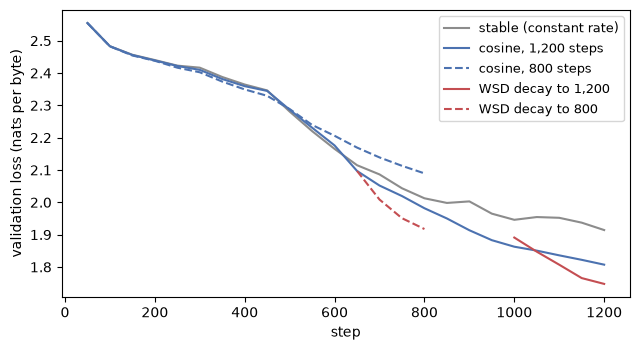

In [17]:
steps = np.arange(EVERY, 1201, EVERY)
mean = {key: np.mean([fn(RUNS[s]) for s in RUNS], axis=0) for key, fn in {
    "stable": lambda r: r["stable"],
    "cosine 1200": lambda r: r["cosine"][1200],
    "cosine 800": lambda r: r["cosine"][800],
    "wsd 1200": lambda r: r["wsd"][1200]["curve"],
    "wsd 800": lambda r: r["wsd"][800]["curve"],
}.items()}
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(steps, mean["stable"], color="#8c8c8c", label="stable (constant rate)")
ax.plot(steps, mean["cosine 1200"], color="#4c72b0", label="cosine, 1,200 steps")
ax.plot(steps[:16], mean["cosine 800"], color="#4c72b0", ls="--",
        label="cosine, 800 steps")
ax.plot(steps[19:], mean["wsd 1200"], color="#c44e52", label="WSD decay to 1,200")
ax.plot(steps[12:16], mean["wsd 800"], color="#c44e52", ls="--",
        label="WSD decay to 800")
ax.set_xlabel("step")
ax.set_ylabel("validation loss (nats per byte)")
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

(nb-train-scaling)=
## Scaling: Two Fits of the Chinchilla Data

The closed-form compute-optimal size is checked against a numerical minimization along each isoFLOP curve, for both fits, and Llama 3 8B's shape is placed against the optimum of the refit.

In [18]:
from scipy.optimize import brentq, minimize_scalar

FITS = {  # L_inf, c_N, c_D, gamma_N, gamma_D
    "Hoffmann et al.": (1.69, 406.4, 410.7, 0.34, 0.28),
    "Besiroglu et al.": (1.8172, 482.01, 2085.43, 0.3478, 0.3658),
}


def chinchilla_loss(n, d, fit):
    l_inf, c_n, c_d, g_n, g_d = fit
    return l_inf + c_n / n ** g_n + c_d / d ** g_d


def compute_optimal(compute, fit):
    """Parameters and tokens that minimize the fitted loss at 6 N D = compute."""
    _, c_n, c_d, g_n, g_d = fit
    k = (g_n * c_n / (g_d * c_d)) ** (1 / (g_n + g_d))
    n = k * (compute / 6) ** (g_d / (g_n + g_d))
    return n, compute / (6 * n)


def isoflop_loss(log_n, compute, fit):
    """Fitted loss of a model of 10**log_n parameters trained with `compute` FLOPs."""
    return chinchilla_loss(10 ** log_n, compute / (6 * 10 ** log_n), fit)


for name, fit in FITS.items():
    for compute in np.logspace(19, 26, 8):
        closed, _ = compute_optimal(compute, fit)
        result = minimize_scalar(isoflop_loss, args=(compute, fit), bounds=(5, 15),
                                 method="bounded", options={"xatol": 1e-10})
        assert abs(math.log10(closed) - result.x) < 1e-6
    n, d = compute_optimal(5.88e23, fit)
    print(f"{name}: at Chinchilla's budget N = {n / 1e9:.1f}B, D = {d / 1e12:.2f}T")
    print(f"  ({d / n:.1f} tokens per parameter)")
print("closed form matches the numerical optimum at 8 budgets for both fits")

Hoffmann et al.: at Chinchilla's budget N = 32.5B, D = 3.02T
  (92.8 tokens per parameter)
Besiroglu et al.: at Chinchilla's budget N = 73.0B, D = 1.34T
  (18.4 tokens per parameter)
closed form matches the numerical optimum at 8 budgets for both fits


In [19]:
fit = FITS["Besiroglu et al."]
n, d = 8.03e9, 15e12
loss = chinchilla_loss(n, d, fit)
same_loss = brentq(lambda c: chinchilla_loss(*compute_optimal(c, fit), fit) - loss,
                   1e21, 6 * n * d)
n_small, _ = compute_optimal(same_loss, fit)
print(f"Llama 3 8B shape: {6 * n * d / same_loss:.1f}x the compute of the optimum")
print(f"at equal fitted loss; that optimum has {n_small / 1e9:.0f}B parameters")
assert 5 < 6 * n * d / same_loss < 6 and 30e9 < n_small < 40e9

Llama 3 8B shape: 5.5x the compute of the optimum
at equal fitted loss; that optimum has 34B parameters


In [20]:
def deepseek_llm_hyperparameters(compute):
    """DeepSeek LLM's fitted optimal learning rate and batch size (tokens)."""
    return 0.3118 * compute ** -0.1250, 0.2920 * compute ** 0.3271


lrs, batches = zip(*(deepseek_llm_hyperparameters(c) for c in (1e20, 1e22, 1e24)))
print("learning rates", [f"{x:.2e}" for x in lrs])
print("batch sizes (M tokens)", [round(x / 1e6, 2) for x in batches])
assert lrs[0] > lrs[1] > lrs[2] and batches[0] < batches[1] < batches[2]

learning rates ['9.86e-04', '5.54e-04', '3.12e-04']
batch sizes (M tokens) [1.02, 4.59, 20.69]


## Summary

- Dividing summed micro-batch losses by the token count of the whole batch reproduces the one-batch gradient; the mean of micro-batch means does not.
- The z-loss drives the log-normalizer to zero without changing a single predicted probability.
- Span corruption, the prefix-LM mask and fill-in-the-middle are each undone exactly, and they differ in the share of positions that carry a loss.
- A hand-written AdamW step matches PyTorch's; a short second-moment memory removes the large steps after a sudden change in the gradient; Muon's Newton-Schulz steps bring the singular values of a random matrix into a band around one, all of them when the matrix is rectangular.
- In the small model, decay branches taken from one constant-rate run end below that run and below the cosine runs of the same lengths.
- The closed-form compute-optimal size matches a numerical minimization, and the published fit and the refit of the Chinchilla data disagree widely in the model size they recommend.